In [ ]:
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

# 0. Подготовка данных

In [ ]:
training_data = datasets.CIFAR10(
    root = "data",
    train = True,
    download = True,
    transform = transforms.ToTensor()
)

test_data = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

Смотрим размеры выборок

In [ ]:
print('Размер обучающей выборки:', training_data.data.shape)
print(len(training_data.targets))
print('Размер тестовой выборки:', test_data.data.shape)
print(len(test_data.targets))

Создаем словарь меток классов объектов на изображениях

In [ ]:
labels_dict = {j:i for i, j in training_data.class_to_idx.items()}
labels_dict

Задаем константы

In [ ]:
LEARNING_RATE = 0.001
BATCH_SIZE = 64
EPOCHS = 10

Создаем объект DataLoader

In [ ]:
train_dataloader = DataLoader(training_data, batch_size = BATCH_SIZE, shuffle = True)
test_dataloader = DataLoader(test_data, batch_size = BATCH_SIZE, shuffle = True)

Определяем устройство для обучения

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device} device")

In [ ]:
def train_loop(dataloader, model, loss_fn, optimizer, device):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        # Forward pass
        X = X.to(device)
        y = y.to(device)

        # Loss calculation
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backward pass
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * BATCH_SIZE + len(X)
            print(f"loss: {loss:>7f} , batch: [{current:>5d}/{size:>5d}]")

In [ ]:
def test_loop(dataloader, model, loss_fn, device):
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    with torch.no_grad():
        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

# 1. ResNET

In [ ]:
class ResNet9(nn.Module):
    def conv_block(self, in_channels, out_channels, pool=False):
      layers = [
          nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
          nn.BatchNorm2d(out_channels),
          nn.ReLU(inplace=True)]
      if pool: layers.append(nn.MaxPool2d(2))
      return nn.Sequential(*layers)

    def __init__(self, in_channels, n_classes):
        super().__init__()

        self.conv1 = self.conv_block(in_channels, 64)
        self.conv2 = self.conv_block(64, 128, pool=True)
        self.res1 = nn.Sequential(self.conv_block(128, 128), self.conv_block(128, 128))

        self.conv3 = self.conv_block(128, 256, pool=True)
        self.conv4 = self.conv_block(256, 512, pool=True)
        self.res2 = nn.Sequential(self.conv_block(512, 512), self.conv_block(512, 512))

        self.classifier = nn.Sequential(nn.MaxPool2d(4),
                                        nn.Flatten(),
                                        nn.Linear(512, n_classes))

    def forward(self, x):
        x = self.conv1(x)       # 64 x 32 x 32
        x = self.conv2(x)       # 128 x 16 x 16
        x = self.res1(x) + x    # 128 x 16 x 16
        x = self.conv3(x)       # 256 x 8 x 8
        x = self.conv4(x)       # 512 x 4 x 4
        x = self.res2(x) + x    # 512 x 4 x 4
        x = self.classifier(x)  # 512 x 1 x 1
        return x

In [ ]:
res_net_model = ResNet9(in_channels = 3, n_classes = 10).to(device)
optimizer = torch.optim.Adam(res_net_model.parameters(), lr = LEARNING_RATE)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, res_net_model, loss_fn, optimizer, device)
    #test_loop(test_dataloader, model, loss_fn, device)
print("Done!")

Epoch 1
-------------------------------
loss: 3.480796 , batch: [   64/50000]
loss: 1.762184 , batch: [ 6464/50000]
loss: 1.487445 , batch: [12864/50000]
loss: 1.168799 , batch: [19264/50000]
loss: 0.880196 , batch: [25664/50000]
loss: 0.860202 , batch: [32064/50000]
loss: 0.957765 , batch: [38464/50000]
loss: 1.101951 , batch: [44864/50000]
Epoch 2
-------------------------------
loss: 0.814814 , batch: [   64/50000]
loss: 0.439809 , batch: [ 6464/50000]
loss: 0.845467 , batch: [12864/50000]
loss: 0.663489 , batch: [19264/50000]
loss: 0.524964 , batch: [25664/50000]
loss: 0.566003 , batch: [32064/50000]
loss: 0.469276 , batch: [38464/50000]
loss: 0.518318 , batch: [44864/50000]
Epoch 3
-------------------------------
loss: 0.296613 , batch: [   64/50000]
loss: 0.313307 , batch: [ 6464/50000]
loss: 0.363890 , batch: [12864/50000]
loss: 0.425920 , batch: [19264/50000]
loss: 0.373526 , batch: [25664/50000]
loss: 0.458246 , batch: [32064/50000]
loss: 0.309747 , batch: [38464/50000]
loss: 

              precision    recall  f1-score   support

    airplane       0.88      0.81      0.84      1000
  automobile       0.95      0.93      0.94      1000
        bird       0.96      0.56      0.71      1000
         cat       0.73      0.76      0.75      1000
        deer       0.84      0.87      0.85      1000
         dog       0.76      0.83      0.79      1000
        frog       0.87      0.90      0.88      1000
       horse       0.88      0.91      0.89      1000
        ship       0.76      0.97      0.86      1000
       truck       0.92      0.92      0.92      1000

    accuracy                           0.85     10000
   macro avg       0.86      0.85      0.84     10000
weighted avg       0.86      0.85      0.84     10000



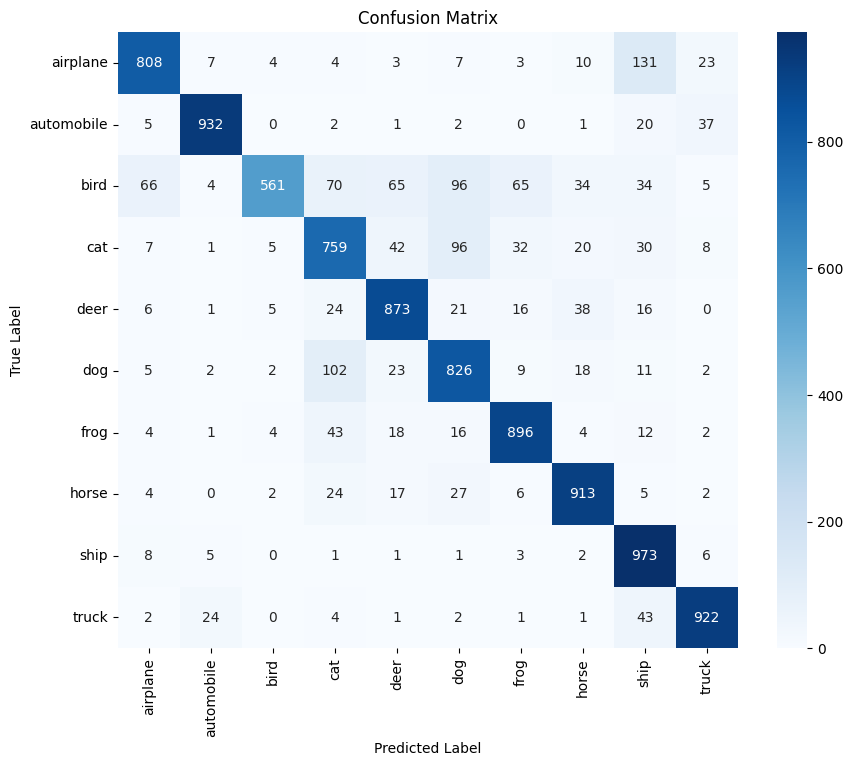

In [ ]:
res_net_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = res_net_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=labels_dict.values()))

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap=plt.cm.Blues, xticklabels=labels_dict.values(), yticklabels=labels_dict.values())
plt.xlabel('Predicted Label')  # x-axis label
plt.ylabel('True Label')       # y-axis label
plt.title('Confusion Matrix')  # Title of the plot
plt.show()

# 2. VGG

In [ ]:
class TinyVGG(nn.Module):
  def __init__(self, in_channels: int, n_classes: int) -> None:
    super().__init__()
    # 2 Свертки
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=in_channels,
                  out_channels=32,
                  kernel_size=3,
                  stride=1,
                  padding=1), # Выход 32 × 32 × 32
        nn.ReLU(),
        nn.Conv2d(in_channels=32,
                  out_channels=32,
                  kernel_size=3,
                  stride=1,
                  padding=1), # Выход 32 × 32 × 32
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2) # Выход: 32 × 16 × 16
    )
    # 3 Свертки
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=32,
                  out_channels=64,
                  kernel_size=3,
                  stride=1,
                  padding=1), # Выход: 64 × 16 × 16
        nn.ReLU(),
        nn.Conv2d(in_channels=64,
                  out_channels=64,
                  kernel_size=3,
                  stride=1,
                  padding=1),# Выход: 64 × 16 × 16
        nn.ReLU(),
        nn.Conv2d(in_channels=64,
                  out_channels=64,
                  kernel_size=3,
                  stride=1,
                  padding=1),# Выход: 64 × 16 × 16
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2) # Выход: 64 × 8 × 8
    )
    # 4 Свертки
    self.conv_block_3 = nn.Sequential(
        nn.Conv2d(in_channels=64,
                  out_channels=128,
                  kernel_size=3,
                  stride=1,
                  padding=1), # Выход: 128 × 8 × 8
        nn.ReLU(),
        nn.Conv2d(in_channels=128,
                  out_channels=128,
                  kernel_size=3,
                  stride=1,
                  padding=1), # Выход: 128 × 8 × 8
        nn.ReLU(),
        nn.Conv2d(in_channels=128,
                  out_channels=128,
                  kernel_size=3,
                  stride=1,
                  padding=1), # Выход: 128 × 8 × 8
        nn.ReLU(),
        nn.Conv2d(in_channels=128,
                  out_channels=128,
                  kernel_size=3,
                  stride=1,
                  padding=1), # Выход: 128 × 8 × 8
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2) # Выход: 128 × 4 × 4
    )

    self.classifier = nn.Sequential(
        nn.Flatten(), # 128 x 4 x 4 = 2048
        nn.Linear(in_features = 128*4*4, out_features = 1024),
        nn.ReLU(),
        nn.Dropout(p=0.5), #add dropout layer to decrease overfitting
        nn.Linear(in_features = 1024, out_features = 512),
        nn.ReLU(),
        nn.Dropout(p=0.5),
        nn.Linear(in_features = 512, out_features=n_classes)
    )

  def forward(self, x: torch.Tensor):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.classifier(x)
        return x

In [ ]:
vgg_model = TinyVGG(in_channels = 3, n_classes = 10).to(device)
optimizer = torch.optim.Adam(vgg_model.parameters(), lr = LEARNING_RATE)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, vgg_model, loss_fn, optimizer, device)
    #test_loop(test_dataloader, model, loss_fn, device)
print("Done!")

Epoch 1
-------------------------------
loss: 2.298859 , batch: [   64/50000]
loss: 2.299427 , batch: [ 6464/50000]
loss: 2.303232 , batch: [12864/50000]
loss: 2.304000 , batch: [19264/50000]
loss: 2.014191 , batch: [25664/50000]
loss: 1.693731 , batch: [32064/50000]
loss: 1.967548 , batch: [38464/50000]
loss: 1.824988 , batch: [44864/50000]
Epoch 2
-------------------------------
loss: 1.645784 , batch: [   64/50000]
loss: 1.583004 , batch: [ 6464/50000]
loss: 1.781902 , batch: [12864/50000]
loss: 1.826881 , batch: [19264/50000]
loss: 1.730544 , batch: [25664/50000]
loss: 1.511373 , batch: [32064/50000]
loss: 1.602544 , batch: [38464/50000]
loss: 1.508637 , batch: [44864/50000]
Epoch 3
-------------------------------
loss: 1.485563 , batch: [   64/50000]
loss: 1.410502 , batch: [ 6464/50000]
loss: 1.627324 , batch: [12864/50000]
loss: 1.417042 , batch: [19264/50000]
loss: 1.342460 , batch: [25664/50000]
loss: 1.594860 , batch: [32064/50000]
loss: 1.602575 , batch: [38464/50000]
loss: 

              precision    recall  f1-score   support

    airplane       0.69      0.71      0.70      1000
  automobile       0.87      0.82      0.85      1000
        bird       0.55      0.46      0.50      1000
         cat       0.42      0.58      0.49      1000
        deer       0.51      0.62      0.56      1000
         dog       0.75      0.31      0.44      1000
        frog       0.64      0.82      0.72      1000
       horse       0.70      0.69      0.70      1000
        ship       0.79      0.80      0.79      1000
       truck       0.85      0.77      0.80      1000

    accuracy                           0.66     10000
   macro avg       0.68      0.66      0.65     10000
weighted avg       0.68      0.66      0.65     10000



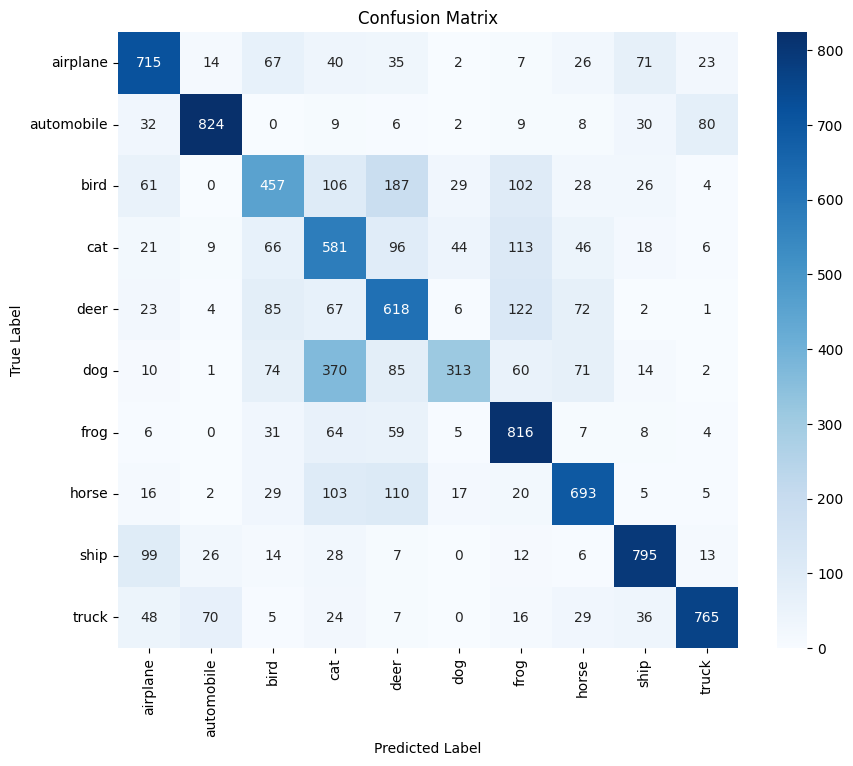

In [ ]:
vgg_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = vgg_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=labels_dict.values()))

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap=plt.cm.Blues, xticklabels=labels_dict.values(), yticklabels=labels_dict.values())
plt.xlabel('Predicted Label')  # x-axis label
plt.ylabel('True Label')       # y-axis label
plt.title('Confusion Matrix')  # Title of the plot
plt.show()

# 3. Обнаружение объектов с YOLO



In [3]:
# !pip install ultralytics

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image, ImageDraw
from datasets import load_dataset, Dataset
from functools import partial
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
iterable_ds = load_dataset(
    "detection-datasets/coco",
    data_files = {
        "train": "data/train-00000-of-00040-67e35002d152155c.parquet",
        },
     streaming=True)

def gen_from_iterable_dataset(iterable_ds):
    yield from iterable_ds

dataset = Dataset.from_generator(partial(gen_from_iterable_dataset, iterable_ds["train"]), features = iterable_ds["train"].features)

print(dataset)

README.md:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['image_id', 'image', 'width', 'height', 'objects'],
    num_rows: 2932
})


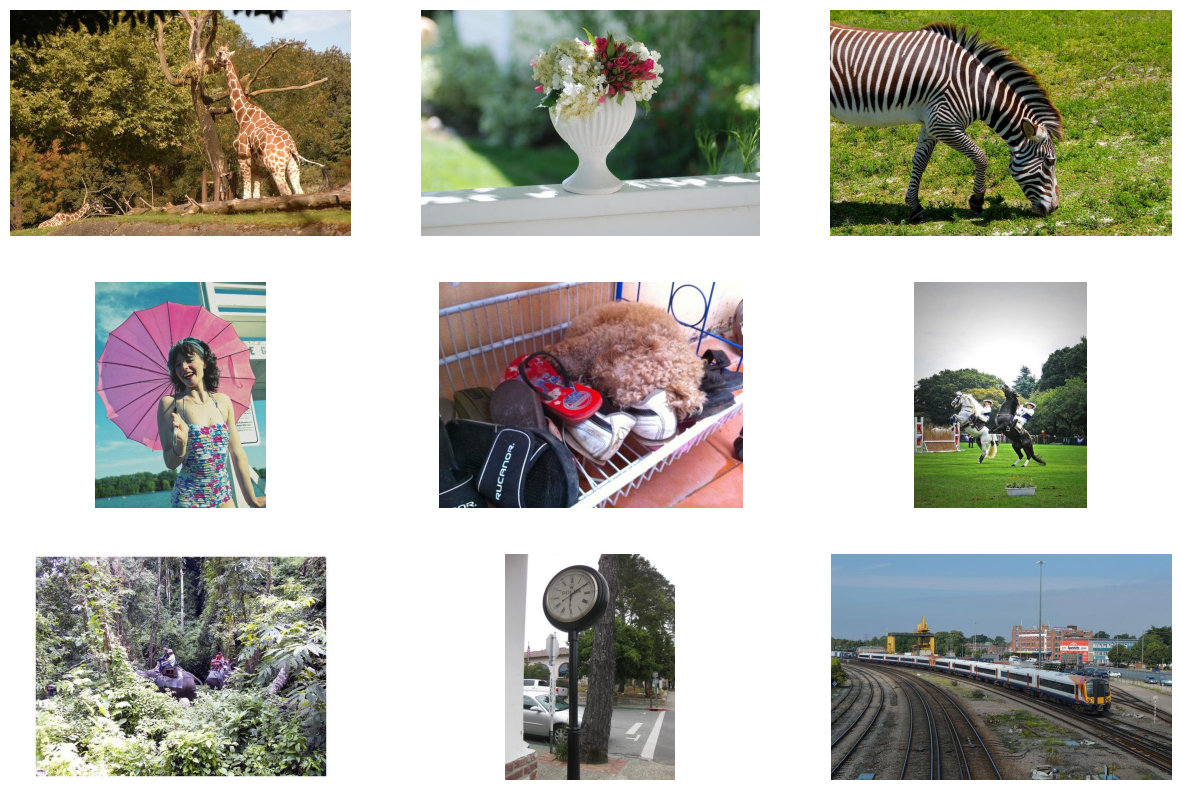

In [15]:
# Посмотрим на несколько картинок
figure = plt.figure(figsize=(15, 10))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    img = dataset[i]["image"]
    figure.add_subplot(rows, cols, i)
    plt.axis("off")
    plt.imshow(img)
plt.show()

In [17]:
# Грузим модель
model = YOLO("yolo26n.pt")
model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

In [18]:
# Берем произвольный рисунок
image= dataset[2]["image"]
results = model(image)


0: 448x640 1 potted plant, 1 vase, 10.3ms
Speed: 128.9ms preprocess, 10.3ms inference, 38.8ms postprocess per image at shape (1, 3, 448, 640)


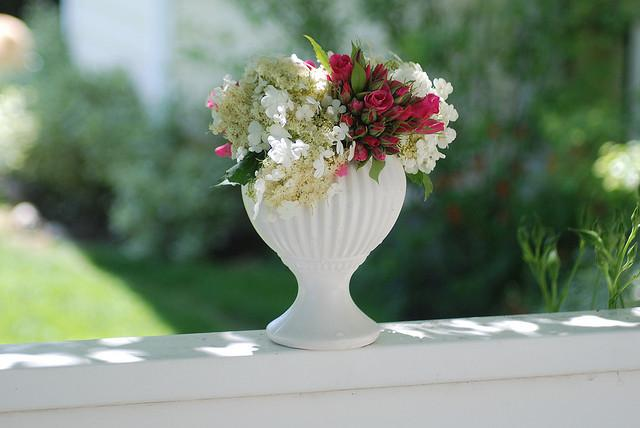

In [20]:
# Смотрим исходный рисунок
image

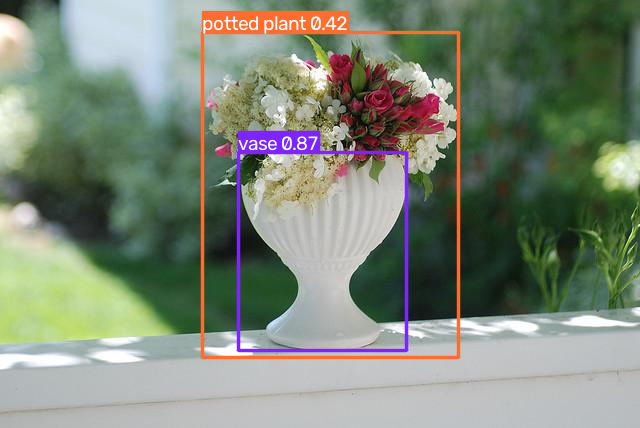

In [23]:
# Смотрим результаты
results[0].show()

In [24]:
# Сохраняем рисунок с рамками
results[0].save(filename="yolo_output.jpg")

'yolo_output.jpg'

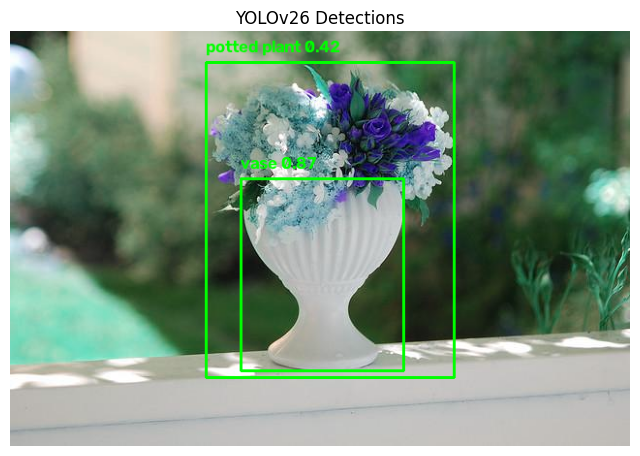

In [26]:
# Показать детали предсказания
result = results[0]
boxes = result.boxes.xyxy  # [x1, y1, x2, y2]
scores = result.boxes.conf  # confidence
classes = result.boxes.cls  # class IDs
names = result.names        # class name mapping

# Нарисуем вручную рамки для изображения
img_cv = np.array(image)
for (x1, y1, x2, y2), conf, cls in zip(boxes, scores, classes):
    label = f"{names[int(cls)]} {conf:.2f}"
    cv2.rectangle(img_cv, (int(x1), int(y1)), (int(x2), int(y2)), (0,255,0), 2)
    cv2.putText(img_cv, label, (int(x1), int(y1)-10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

plt.figure(figsize=(8,8))
plt.imshow(cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB))
plt.title("YOLOv26 Detections")
plt.axis("off")
plt.show()


0: 480x640 4 bowls, 2 broccolis, 133.6ms
Speed: 7.6ms preprocess, 133.6ms inference, 2.7ms postprocess per image at shape (1, 3, 480, 640)


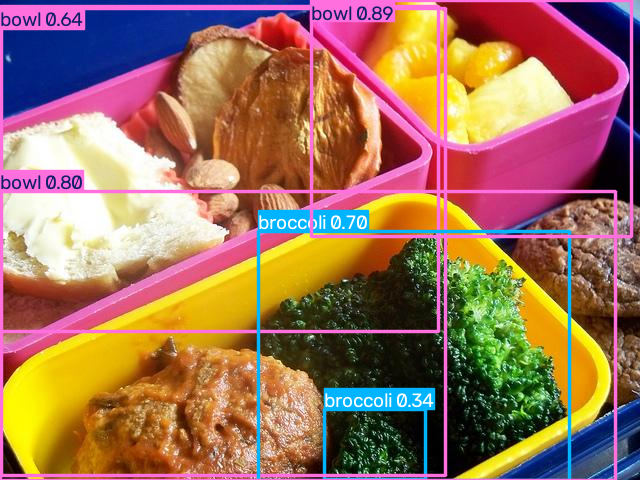


0: 448x640 1 giraffe, 30.2ms
Speed: 1.0ms preprocess, 30.2ms inference, 2.4ms postprocess per image at shape (1, 3, 448, 640)


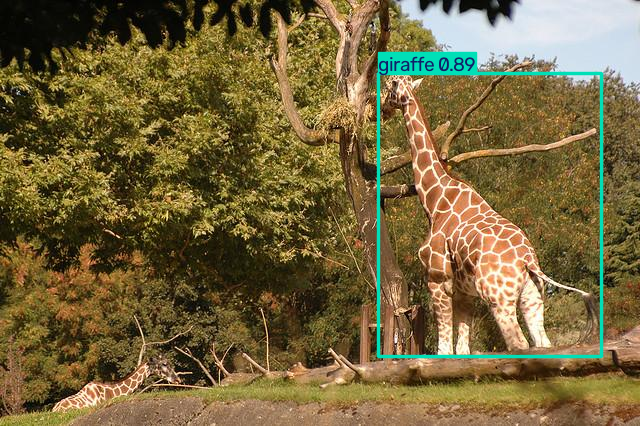


0: 448x640 1 potted plant, 1 vase, 22.5ms
Speed: 1.2ms preprocess, 22.5ms inference, 6.2ms postprocess per image at shape (1, 3, 448, 640)


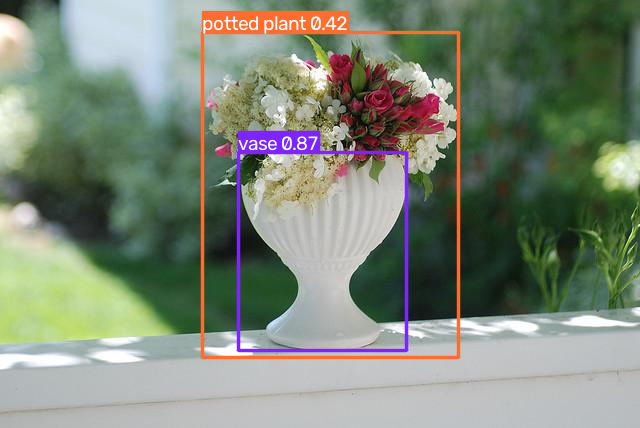

In [27]:
# Пробуем применить модель к нескольким изображениям
for i in range(3):
    img = dataset[i]["image"]
    res = model(img)
    res[0].show()

# 4. Сегментация объектов

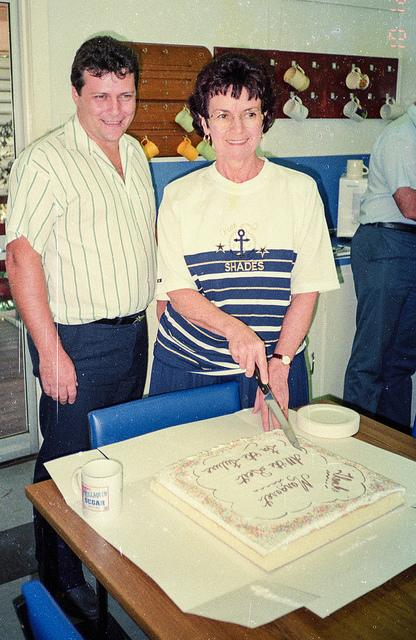

In [29]:
dataset[22]["image"]

In [28]:
model = YOLO("yolo26n-seg.pt") # Внимание, модель для сегментации

results = model.predict(
    source=dataset[22]["image"],
    conf=0.25,
    save=True,
)

for result in results:
    if result.masks is None:
        print("Объекты не найдены")
        continue

    # Маски всех обнаруженных объектов
    masks = result.masks.data

    print("Форма тензора масок:", masks.shape)


0: 640x416 3 persons, 1 cup, 1 knife, 1 bowl, 1 cake, 2 chairs, 1 dining table, 14.0ms
Speed: 1.6ms preprocess, 14.0ms inference, 58.9ms postprocess per image at shape (1, 3, 640, 416)
Results saved to /content/runs/segment/predict
Форма тензора масок: torch.Size([10, 640, 416])


result.masks.data содержит маски объектов в виде тензора.

В зависимости от версии API и настроек предсказания их пространственный размер может отличаться от исходного изображения.

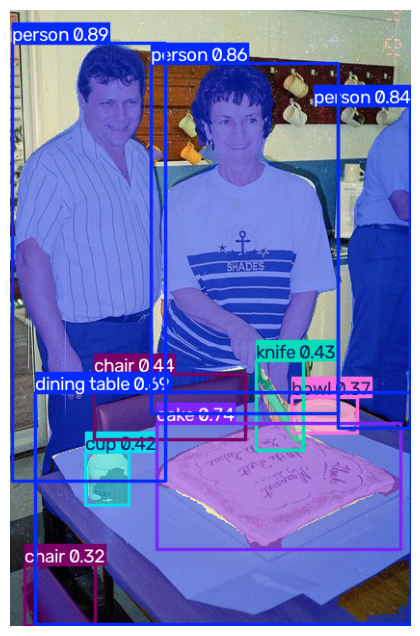

In [30]:
# Показываем изображение с рамками
annotated_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

# 5. Определение позы человека

In [48]:
model = YOLO("yolo26n-pose.pt")

results = model.predict(
    source=dataset[62]["image"],
    conf=0.3,
    save=True,
)

for result in results:
    if result.keypoints is None:
        continue

    # Координаты ключевых точек каждого найденного человека
    keypoints_xy = result.keypoints.xy

    # Оценки уверенности ключевых точек, если доступны
    keypoints_conf = result.keypoints.conf

    print("Координаты точек:", keypoints_xy.shape)


0: 640x480 8 persons, 19.9ms
Speed: 1.3ms preprocess, 19.9ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/pose/predict-2
Координаты точек: torch.Size([8, 17, 2])


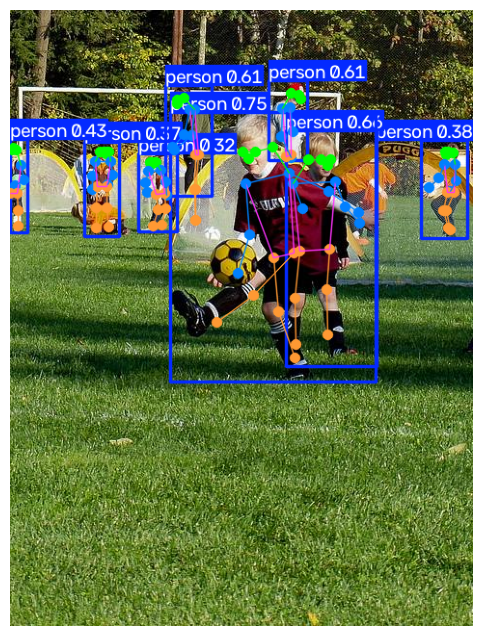

In [49]:
# Показываем изображение с рамками
annotated_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

# 6. Подсчет объектов


0: 448x640 5 persons, 11.7ms
Speed: 0.9ms preprocess, 11.7ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)
Количество объектов на изображении:
person: 5

Всего обнаружено объектов: 5


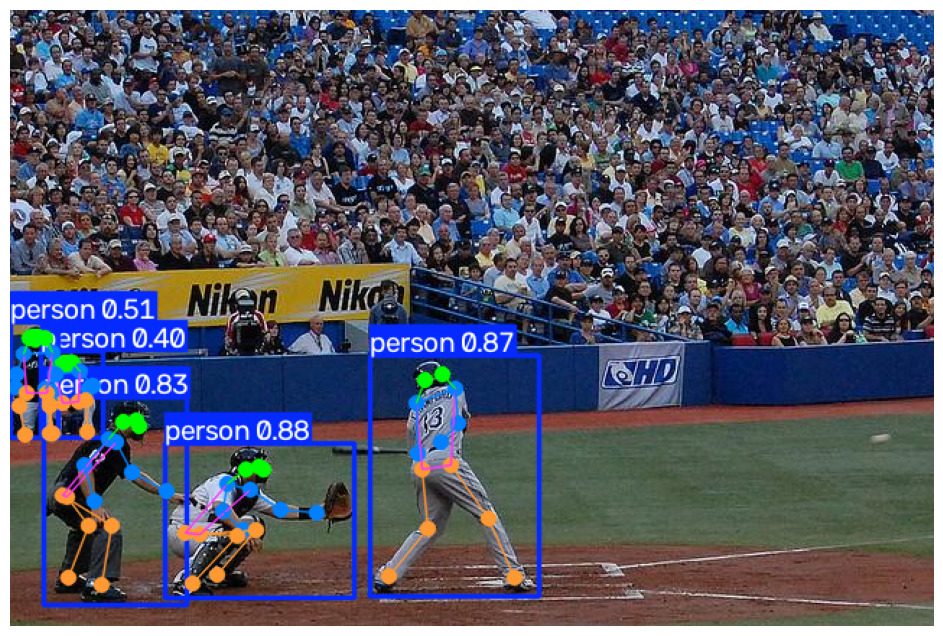

In [62]:
from collections import Counter

model = YOLO("yolo26n-pose.pt")

results = model.predict(
    source=dataset[100]["image"],
    conf=0.25,
)

result = results[0]

# Получаем классы обнаруженных объектов
class_ids = result.boxes.cls.int().tolist()
class_names = [
    result.names[class_id]
    for class_id in class_ids
]

# Считаем количество объектов каждого класса
counts = Counter(class_names)

print("Количество объектов на изображении:")

for class_name, count in counts.most_common():
    print(f"{class_name}: {count}")

print(f"\nВсего обнаружено объектов: {len(class_names)}")

# Показываем изображение с рамками
annotated_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()

# 7. YOLO для видеопотока

In [ ]:
from ultralytics import YOLO
import cv2

In [ ]:
model = YOLO("yolo26n-pose.pt")

In [ ]:
# Initialize webcam (0 = default camera)
cap = cv2.VideoCapture(0)

# Check camera access
if not cap.isOpened():
    print("Cannot open camera")
else:
    print("Webcam connected. Press 'q' to quit.")

# Run real-time detection
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # Run YOLO inference
    results = model(frame, stream=True)

    # Loop over detections and render them on the frame
    for r in results:
        annotated_frame = r.plot()  # YOLO’s built-in annotation (fast, efficient)

    # Display the frame
    cv2.imshow("YOLOv8 Live Detection", annotated_frame)

    # Quit with 'q'
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Release resources
cap.release()
cv2.destroyAllWindows()

# Пробуем на визуальном обмане

/tmp/ipykernel_437/889950702.py:3: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imread(image_link)


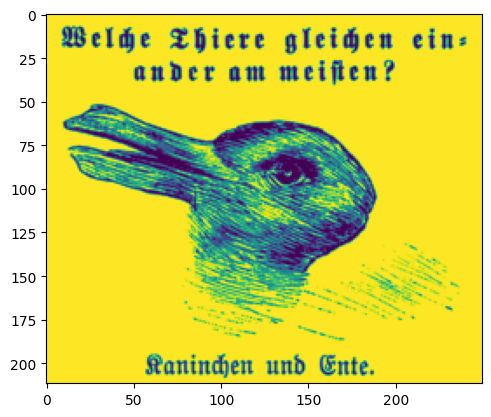

In [50]:
from imageio import imread
image_link = r"/content/Kaninchen_und_Ente.png"
img = imread(image_link)
plt.imshow(img)

In [51]:
# Грузим модель
model = YOLO("yolo26n.pt")
model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)


0: 544x640 1 bird, 21.3ms
Speed: 6.5ms preprocess, 21.3ms inference, 2.4ms postprocess per image at shape (1, 3, 544, 640)


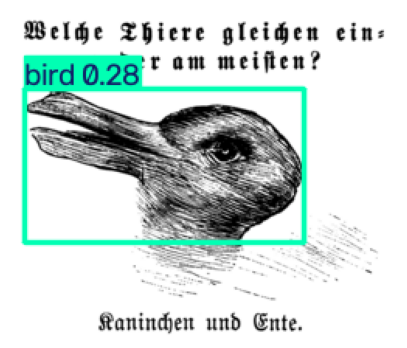

In [58]:
results = model(img)
annotated_image = results[0].plot()

plt.figure(figsize=(5, 5))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.show()